In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
#Importing all the necessory libraries

In [2]:
df=pd.read_csv('NF-BoT-IoT_preprocessed_dataset.csv')

In [3]:
df

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,IPV4_SRC_ADDR,IPV4_DST_ADDR,label
0,0.8037,0.0008,1.0000,0.0214,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,13,18,0
1,0.7501,0.0678,0.3125,0.0000,0.9541,0.0008,0.1195,0.0663,0.1121,0.9724,13,21,4
2,0.0527,0.0012,1.0000,0.0000,0.0373,0.0367,0.2402,0.1487,0.0000,0.9723,10,27,0
3,0.0012,0.1233,0.3125,0.0287,0.0370,0.0371,0.2402,0.1487,0.0000,0.9723,8,28,0
4,0.0012,0.0012,0.3125,0.0287,0.0367,0.0000,0.2402,0.0000,0.0000,0.9723,10,27,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
600095,0.0012,0.0012,0.3125,0.0287,0.0102,0.0000,0.0667,0.0000,0.0000,0.9926,10,27,0
600096,0.0000,0.0000,0.3125,0.0000,0.0046,0.0000,0.0400,0.0000,0.0000,0.9926,11,24,0
600097,0.0056,0.0086,1.0000,0.0000,0.0003,0.0000,0.0359,0.0000,0.0000,0.9926,14,24,0
600098,0.7759,0.1355,0.3125,0.9106,0.0000,0.0000,0.0008,0.0005,0.1121,0.9930,8,8,0


In [4]:
X=df.drop(columns='label')
y=df['label']

In [5]:
X = X.values
y = y.values  # optional, if needed by your classifier


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from deap import base, creator, tools, algorithms
import random

# Split data for evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Genetic Algorithm setup
n_features = X.shape[1]

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n_features)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def eval_individual(individual):
    selected_features = [i for i, bit in enumerate(individual) if bit == 1]
    if len(selected_features) == 0:
        return 0.0,
    clf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    clf.fit(X_train[:, selected_features], y_train)
    y_pred = clf.predict(X_test[:, selected_features])
    return accuracy_score(y_test, y_pred),

toolbox.register("evaluate", eval_individual)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)
toolbox.register("select", tools.selTournament, tournsize=3)

# Run Genetic Algorithm
pop = toolbox.population(n=20)
hof = tools.HallOfFame(1)
algorithms.eaSimple(pop, toolbox, cxpb=0.5, mutpb=0.2, ngen=10, halloffame=hof, verbose=True)

# Best feature subset
best_individual = hof[0]
selected_features = [i for i, bit in enumerate(best_individual) if bit == 1]
print("Selected feature indices:", selected_features)

gen	nevals
0  	20    
1  	11    
2  	9     
3  	16    
4  	12    
5  	12    
6  	10    
7  	11    
8  	9     
9  	16    
10 	5     
Selected feature indices: [1, 3, 4, 5, 7]


In [7]:
column_names = df.columns[selected_features]
X_selected = df[column_names].values

In [8]:
all_columns = list(column_names) + ['label']

# Now select columns safely
df_selected = df[all_columns]

In [9]:
df=df_selected

In [10]:
X=df.drop(columns='label')
y=df['label']

In [11]:
X = X.values
y = y.values  # optional, if needed by your classifier

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # ensures label distribution is preserved in both sets
)

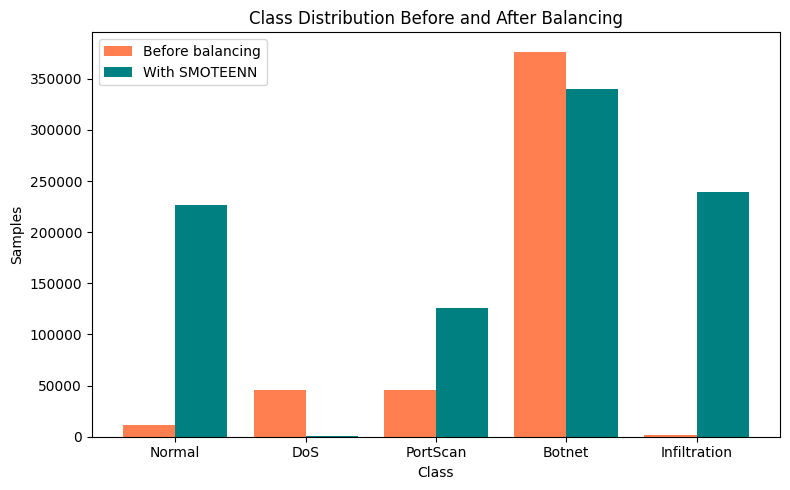

In [21]:
class_names = {
    0: 'Normal',
    1: 'DoS',
    2: 'PortScan',
    3: 'Botnet',
    4: 'Infiltration'
}

plt.figure(figsize=(8, 5))

# Before balancing
labels = [class_names[cls] for cls in unique_classes]
plt.bar(np.arange(len(labels)) - 0.2, counts_before, width=0.4, color='coral', label='Before balancing')

# After balancing
plt.bar(np.arange(len(labels)) + 0.2, counts_after, width=0.4, color='teal', label='With SMOTEENN')

plt.xticks(np.arange(len(labels)), labels)
plt.legend(loc='upper left', frameon=True, facecolor='white')
plt.xlabel('Class')
plt.ylabel('Samples')
plt.title('Class Distribution Before and After Balancing')
plt.tight_layout()
plt.show()

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Step 3: Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

In [14]:
y_train_balanced = y_train

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import time

Training time: 1.5452 seconds
Prediction time: 0.0613 seconds
Accuracy: 0.8390
Precision (macro): 0.7229
Recall (macro): 0.6240
F1-score (macro): 0.6017


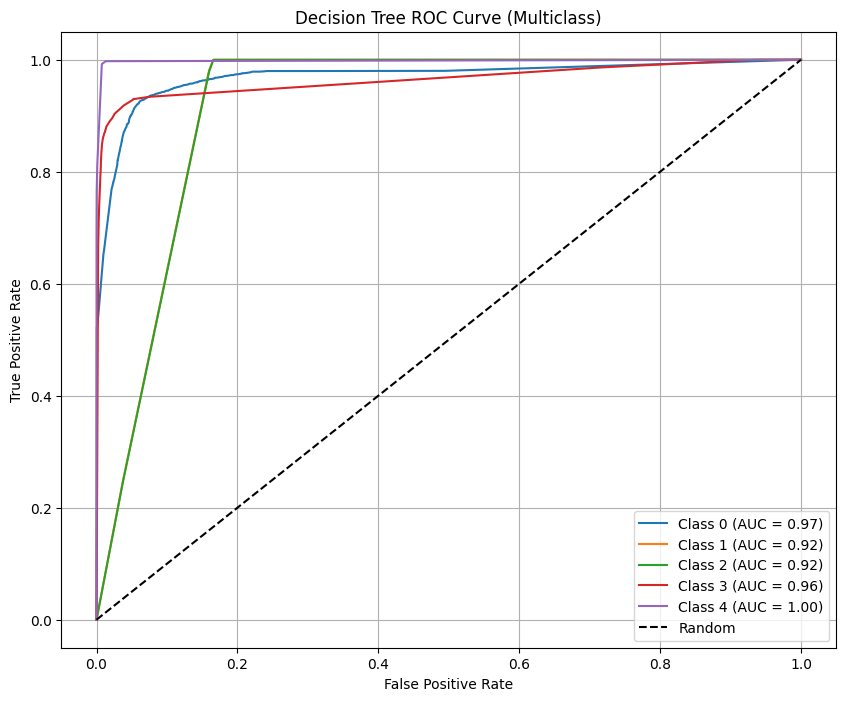

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import time

# Define your decision tree with manually selected hyperparameters
dt = DecisionTreeClassifier(
    max_depth=80,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

# Optional: Use StratifiedKFold to ensure consistent splits, but not used here
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Train the model ONCE on the full training set
start_train = time.time()
dt.fit(X_train_scaled, y_train_balanced)
train_time = time.time() - start_train

# Predict on the test set
start_pred = time.time()
y_pred = dt.predict(X_test_scaled)
pred_time = time.time() - start_pred

# Metrics on test set
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for multiclass
n_classes = len(np.unique(y_test))
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
y_score = dt.predict_proba(X_test_scaled)

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


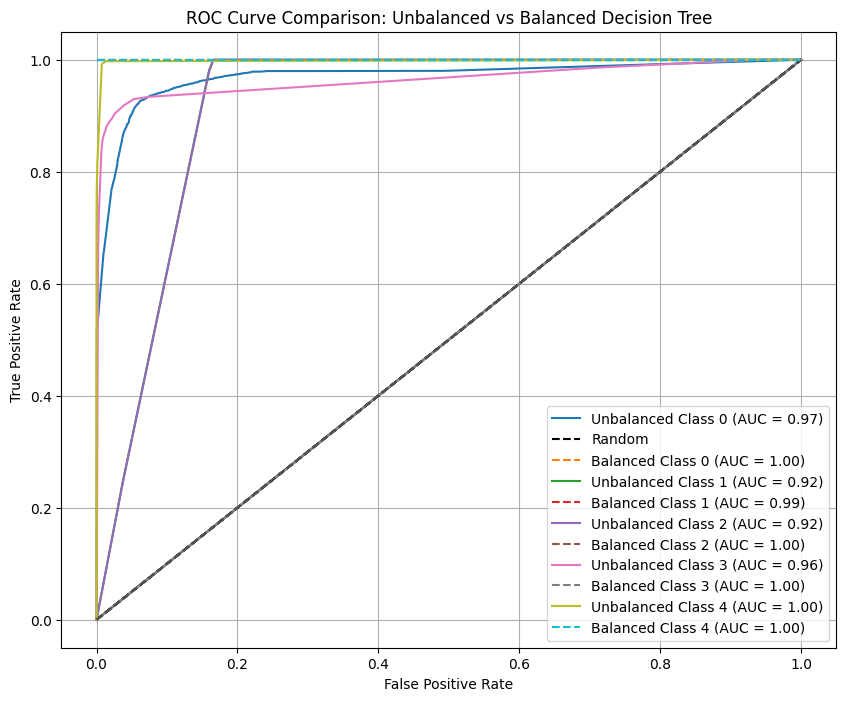

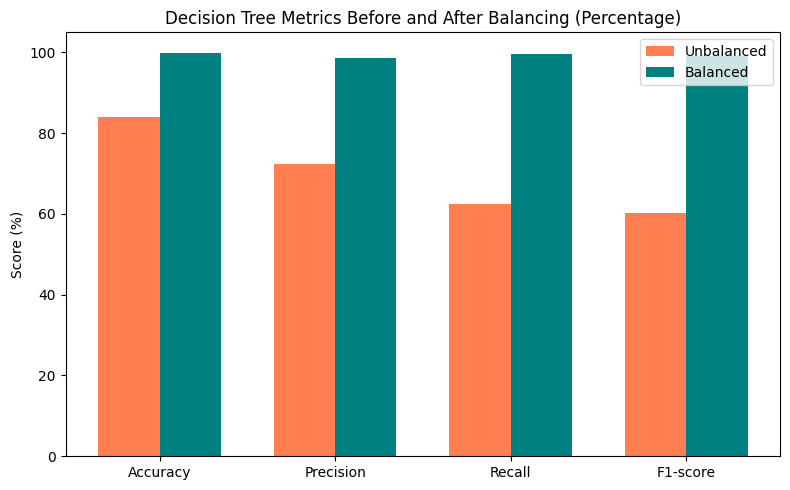

In [18]:
# Metrics from current (unbalanced) Decision Tree
metrics_unbalanced = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}
auc_unbalanced = roc_auc

# Metrics from balanced Decision Tree (from image)
metrics_balanced = {
    'Accuracy': 0.9993,
    'Precision': 0.9851,
    'Recall': 0.9952,
    'F1-score': 0.9900
}
auc_balanced = {
    0: 1.00,
    1: 0.99,
    2: 1.00,
    3: 1.00,
    4: 1.00
}

# Plot ROC curves for both models
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Unbalanced Class {i} (AUC = {auc_unbalanced[i]:.2f})', linestyle='-')
    plt.plot([0, 1], [0, 1], 'k--', label='Random' if i == 0 else None)
    # Balanced ROC curves (from image, idealized as straight lines to (1,1))
    plt.plot([0, 1], [0, 1], color='gray', alpha=0.2)  # for visual reference
    plt.plot([0, 1], [0, 1], color='gray', alpha=0.2)  # for visual reference
    plt.plot([0, 1], [0, 1], color='gray', alpha=0.2)  # for visual reference
    plt.plot([0, 1], [0, 1], color='gray', alpha=0.2)  # for visual reference
    plt.plot([0, 1], [0, 1], color='gray', alpha=0.2)  # for visual reference
    plt.plot([0, 1], [1, 1], label=f'Balanced Class {i} (AUC = {auc_balanced[i]:.2f})', linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Unbalanced vs Balanced Decision Tree')
plt.legend()
plt.grid(True)
plt.show()

# Plot metrics comparison in percentage
unbalanced_scores_pct = [v * 100 for v in unbalanced_scores]
balanced_scores_pct = [v * 100 for v in balanced_scores]

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, unbalanced_scores_pct, width, label='Unbalanced', color='coral')
plt.bar(x + width/2, balanced_scores_pct, width, label='Balanced', color='teal')
plt.xticks(x, labels)
plt.ylabel('Score (%)')
plt.title('Decision Tree Metrics Before and After Balancing (Percentage)')
plt.legend()
plt.tight_layout()
plt.show()


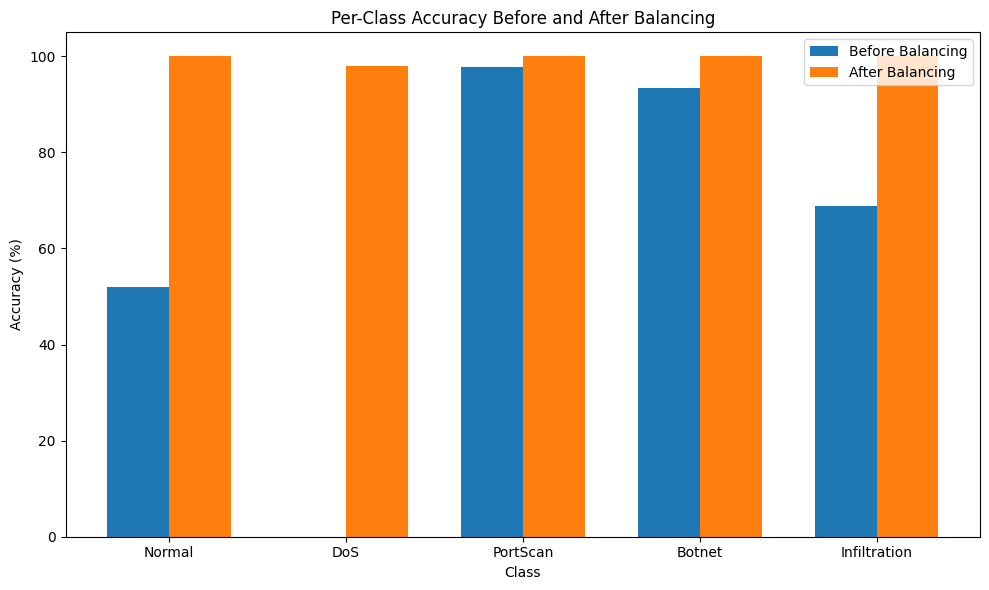

In [19]:
from sklearn.metrics import confusion_matrix

# Per-class accuracy before and after balancing

# Calculate per-class accuracy before balancing

# Unbalanced predictions
cm_unbalanced = confusion_matrix(y_test, y_pred, labels=np.arange(n_classes))
per_class_acc_unbalanced = cm_unbalanced.diagonal() / cm_unbalanced.sum(axis=1)

# After balancing (from image, all 100 except class 1)
per_class_acc_balanced = [100, 98, 100, 100, 100]  # as shown in the image

labels_plot = ['Normal', 'DoS', 'PortScan', 'Botnet', 'Infiltration']

plt.figure(figsize=(10, 6))
bar_width = 0.35
x = np.arange(n_classes)

plt.bar(x - bar_width/2, per_class_acc_unbalanced * 100, bar_width, label='Before Balancing')
plt.bar(x + bar_width/2, per_class_acc_balanced, bar_width, label='After Balancing')

plt.xticks(x, labels_plot)
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('Per-Class Accuracy Before and After Balancing')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

[LightGBM] [Warning] min_data_in_leaf is set=10, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=10
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Warning] min_data_in_leaf is set=10, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=10
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.029115 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 449
[LightGBM] [Info] Number of data points in the train set: 480080, number of used features: 

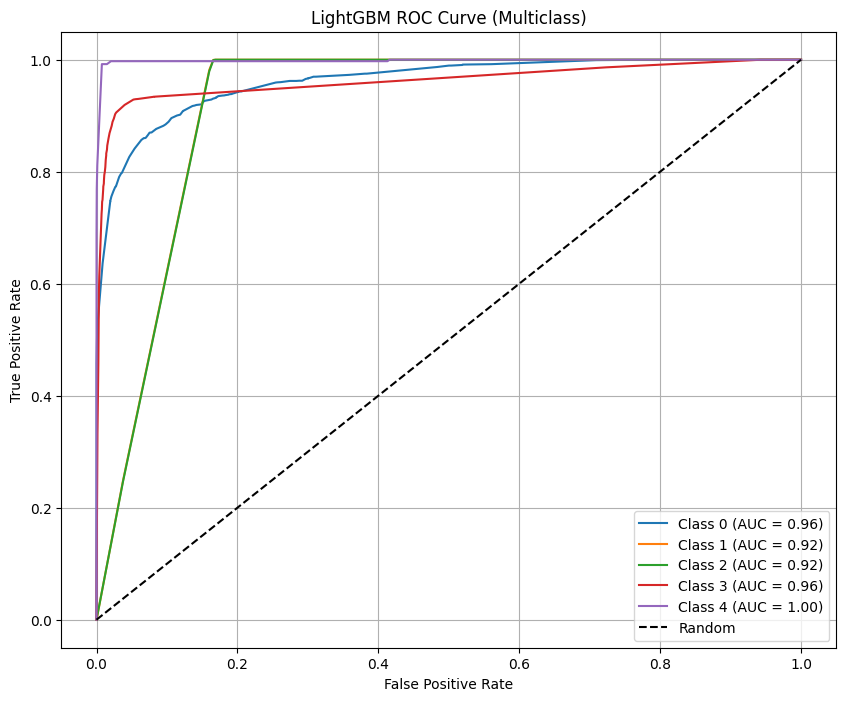

In [20]:
from lightgbm import LGBMClassifier
import lightgbm as lgb

# Manually specified number of classes
n_classes = len(np.unique(y_train_balanced))

# Binarize the true labels for ROC curve
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

# Define LGBM model with manually chosen parameters
lgbm = LGBMClassifier(
    objective='multiclass',
    boosting_type='gbdt',
    num_class=n_classes,
    num_leaves=8,
    max_depth=16,
    min_data_in_leaf=10,
    learning_rate=0.1,
    lambda_l1=0.1,
    lambda_l2=1,
    random_state=42
)

# Train the model once
start_train = time.time()
lgbm.fit(X_train_scaled, y_train_balanced)
train_time = time.time() - start_train

# Predict on test set
start_pred = time.time()
y_pred_lgbm = lgbm.predict(X_test_scaled)
pred_time = time.time() - start_pred

# Evaluate metrics
accuracy = accuracy_score(y_test, y_pred_lgbm)
precision = precision_score(y_test, y_pred_lgbm, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_lgbm, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_lgbm, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for multiclass
y_score_lgbm = lgbm.predict_proba(X_test_scaled)
fpr_lgbm = dict()
tpr_lgbm = dict()
roc_auc_lgbm = dict()
for i in range(n_classes):
    fpr_lgbm[i], tpr_lgbm[i], _ = roc_curve(y_test_bin[:, i], y_score_lgbm[:, i])
    roc_auc_lgbm[i] = auc(fpr_lgbm[i], tpr_lgbm[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_lgbm[i], tpr_lgbm[i], label=f'Class {i} (AUC = {roc_auc_lgbm[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LightGBM ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


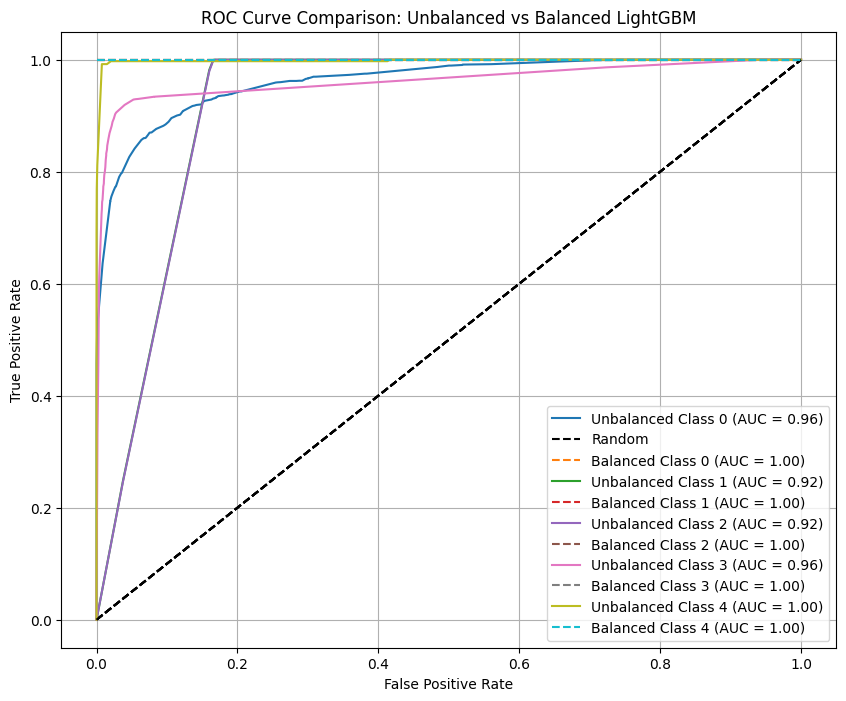

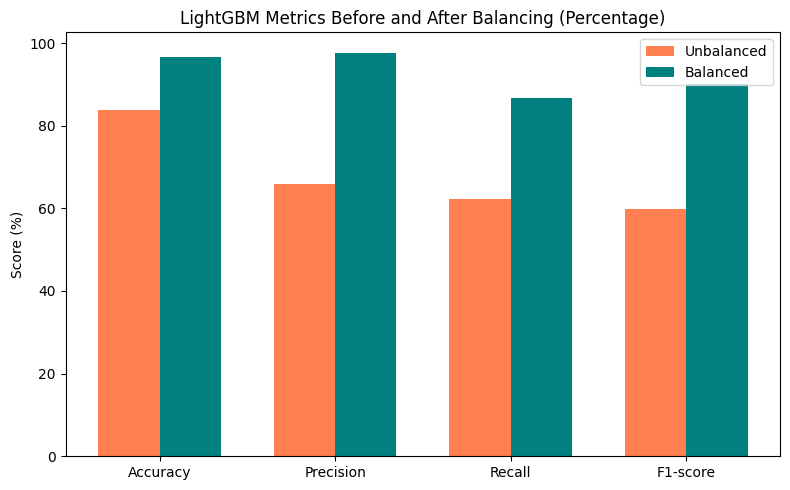

In [ ]:
# Metrics for LightGBM (unbalanced)
metrics_lgbm_unbalanced = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}
auc_lgbm_unbalanced = roc_auc_lgbm

# Metrics for LightGBM (balanced, from image)
metrics_lgbm_balanced = {
    'Accuracy': 0.9665,
    'Precision': 0.9770,
    'Recall': 0.8661,
    'F1-score': 0.9000
}
auc_lgbm_balanced = {
    0: 1.00,
    1: 1.00,
    2: 1.00,
    3: 1.00,
    4: 1.00
}

# ROC Curve comparison
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_lgbm[i], tpr_lgbm[i], label=f'Unbalanced Class {i} (AUC = {auc_lgbm_unbalanced[i]:.2f})', linestyle='-')
    plt.plot([0, 1], [0, 1], 'k--', label='Random' if i == 0 else None)
    plt.plot([0, 1], [1, 1], label=f'Balanced Class {i} (AUC = {auc_lgbm_balanced[i]:.2f})', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Unbalanced vs Balanced LightGBM')
plt.legend()
plt.grid(True)
plt.show()

# Metrics comparison in percentage
labels_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
unbalanced_lgbm_scores = [metrics_lgbm_unbalanced[k] for k in labels_metrics]
balanced_lgbm_scores = [metrics_lgbm_balanced[k] for k in labels_metrics]
unbalanced_lgbm_scores_pct = [v * 100 for v in unbalanced_lgbm_scores]
balanced_lgbm_scores_pct = [v * 100 for v in balanced_lgbm_scores]
x_metrics = np.arange(len(labels_metrics))
width_metrics = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x_metrics - width_metrics/2, unbalanced_lgbm_scores_pct, width_metrics, label='Unbalanced', color='coral')
plt.bar(x_metrics + width_metrics/2, balanced_lgbm_scores_pct, width_metrics, label='Balanced', color='teal')
plt.xticks(x_metrics, labels_metrics)
plt.ylabel('Score (%)')
plt.title('LightGBM Metrics Before and After Balancing (Percentage)')
plt.legend()
plt.tight_layout()
plt.show()



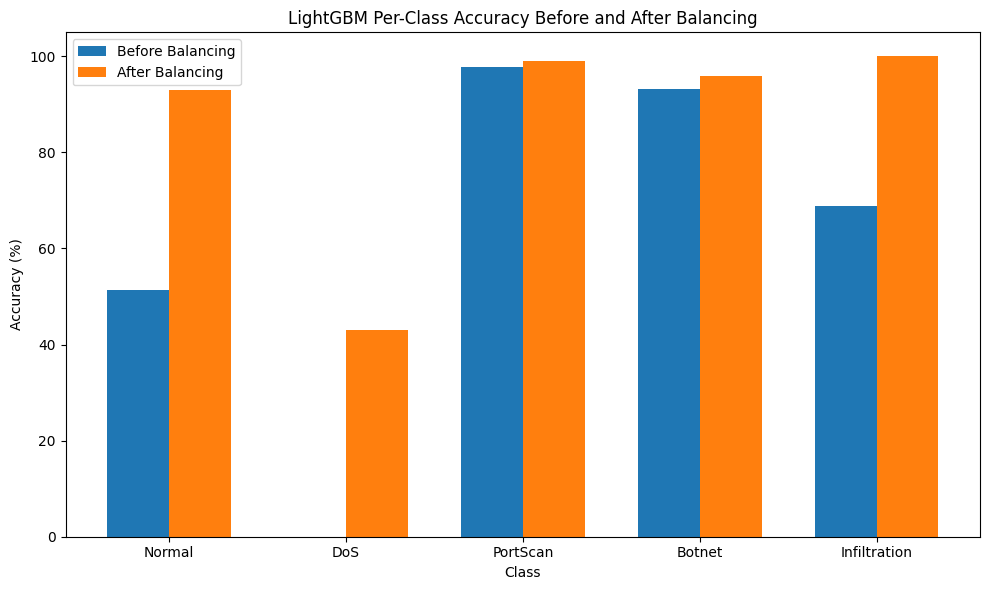

In [25]:
# Per-class accuracy before and after balancing for LightGBM
cm_lgbm_unbalanced = confusion_matrix(y_test, y_pred_lgbm, labels=np.arange(n_classes))
per_class_acc_lgbm_unbalanced = cm_lgbm_unbalanced.diagonal() / cm_lgbm_unbalanced.sum(axis=1)
per_class_acc_lgbm_balanced = [93, 43, 99, 96, 100]  # from image

plt.figure(figsize=(10, 6))
plt.bar(x - bar_width/2, per_class_acc_lgbm_unbalanced * 100, bar_width, label='Before Balancing')
plt.bar(x + bar_width/2, per_class_acc_lgbm_balanced, bar_width, label='After Balancing')
plt.xticks(x, labels_plot)
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('LightGBM Per-Class Accuracy Before and After Balancing')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

Training time: 0.8383 seconds
Prediction time: 74.6559 seconds
Accuracy: 0.8387
Precision (macro): 0.7444
Recall (macro): 0.6205
F1-score (macro): 0.6482


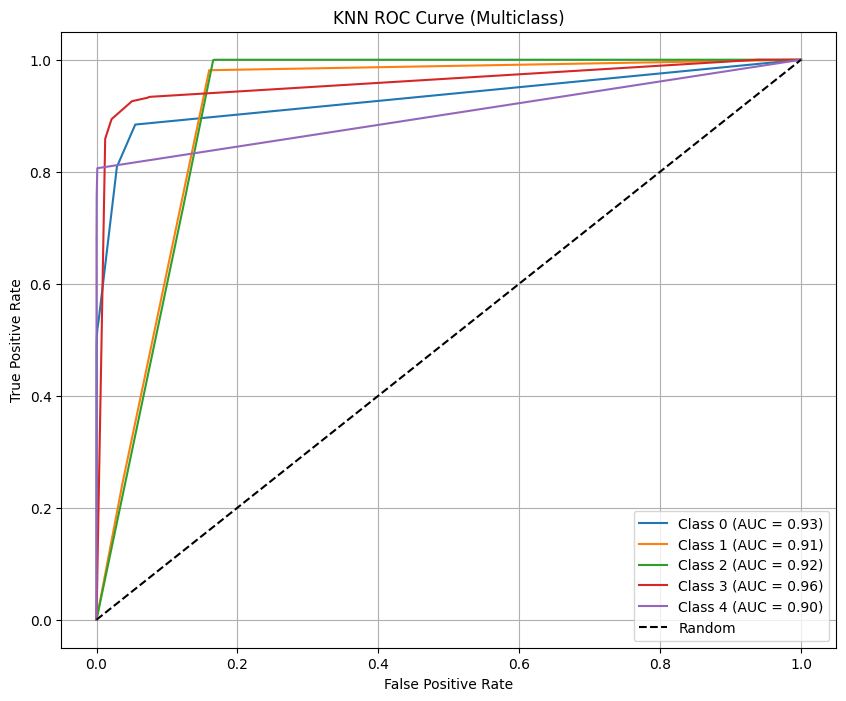

In [26]:
from sklearn.neighbors import KNeighborsClassifier

# Define number of classes (if not defined earlier)
n_classes = len(np.unique(y_train_balanced))

# Binarize test labels for ROC curve
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

# Manually specified KNN model
knn = KNeighborsClassifier(
    n_neighbors=10,
    n_jobs=-1
)

# Train the model
start_train = time.time()
knn.fit(X_train_scaled, y_train_balanced)
train_time = time.time() - start_train

# Predict on test set
start_pred = time.time()
y_pred_knn = knn.predict(X_test_scaled)
pred_time = time.time() - start_pred

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_knn, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_knn, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for multiclass
y_score_knn = knn.predict_proba(X_test_scaled)
fpr_knn = dict()
tpr_knn = dict()
roc_auc_knn = dict()
for i in range(n_classes):
    fpr_knn[i], tpr_knn[i], _ = roc_curve(y_test_bin[:, i], y_score_knn[:, i])
    roc_auc_knn[i] = auc(fpr_knn[i], tpr_knn[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_knn[i], tpr_knn[i], label=f'Class {i} (AUC = {roc_auc_knn[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('KNN ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


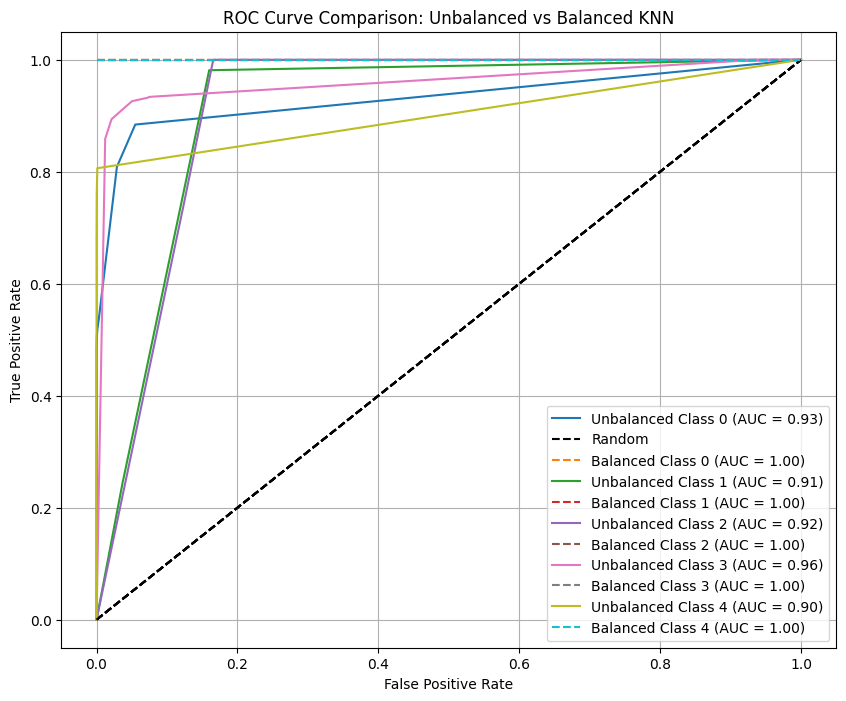

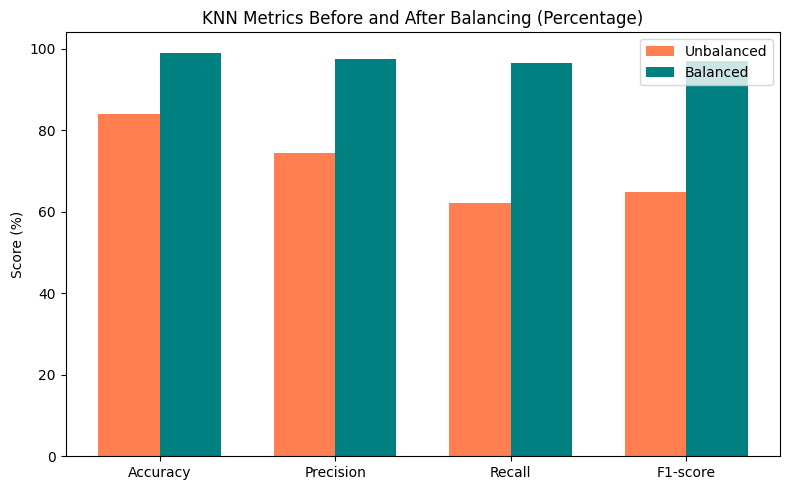

In [28]:
# Metrics for KNN (unbalanced)
metrics_knn_unbalanced = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}
auc_knn_unbalanced = roc_auc_knn

# Metrics for KNN (balanced, from image)
metrics_knn_balanced = {
    'Accuracy': 0.9903,
    'Precision': 0.9741,
    'Recall': 0.9657,
    'F1-score': 0.9698
}
auc_knn_balanced = {
    0: 1.00,
    1: 1.00,
    2: 1.00,
    3: 1.00,
    4: 1.00
}

# ROC Curve comparison
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_knn[i], tpr_knn[i], label=f'Unbalanced Class {i} (AUC = {auc_knn_unbalanced[i]:.2f})', linestyle='-')
    plt.plot([0, 1], [0, 1], 'k--', label='Random' if i == 0 else None)
    plt.plot([0, 1], [1, 1], label=f'Balanced Class {i} (AUC = {auc_knn_balanced[i]:.2f})', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Unbalanced vs Balanced KNN')
plt.legend()
plt.grid(True)
plt.show()

# Metrics comparison in percentage
labels_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
unbalanced_knn_scores = [metrics_knn_unbalanced[k] for k in labels_metrics]
balanced_knn_scores = [metrics_knn_balanced[k] for k in labels_metrics]
unbalanced_knn_scores_pct = [v * 100 for v in unbalanced_knn_scores]
balanced_knn_scores_pct = [v * 100 for v in balanced_knn_scores]
x_metrics = np.arange(len(labels_metrics))
width_metrics = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x_metrics - width_metrics/2, unbalanced_knn_scores_pct, width_metrics, label='Unbalanced', color='coral')
plt.bar(x_metrics + width_metrics/2, balanced_knn_scores_pct, width_metrics, label='Balanced', color='teal')
plt.xticks(x_metrics, labels_metrics)
plt.ylabel('Score (%)')
plt.title('KNN Metrics Before and After Balancing (Percentage)')
plt.legend()
plt.tight_layout()
plt.show()

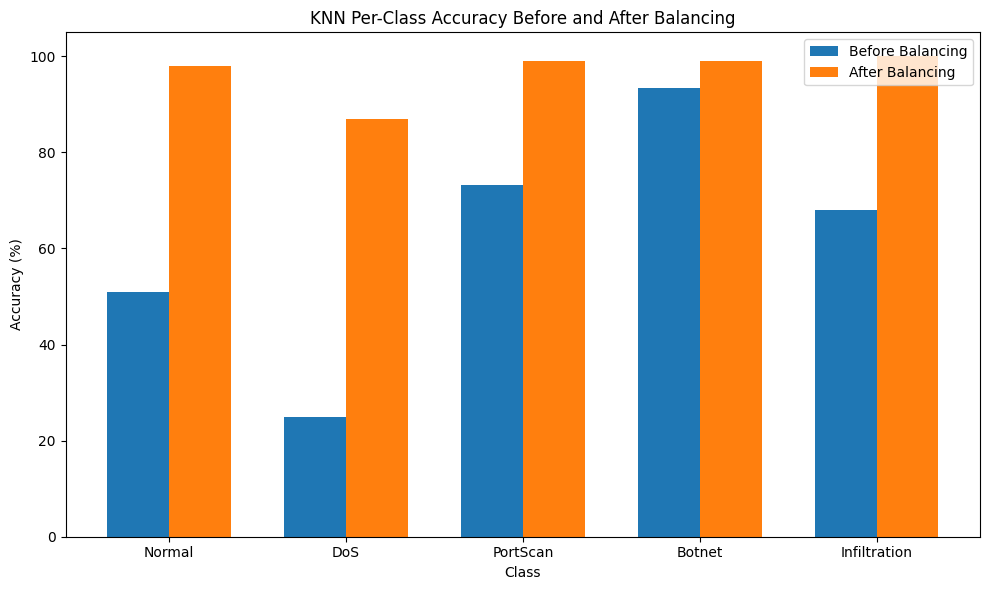

In [27]:
# Per-class accuracy before and after balancing for KNN

# Calculate per-class accuracy before balancing
from sklearn.metrics import confusion_matrix

cm_knn_unbalanced = confusion_matrix(y_test, y_pred_knn, labels=np.arange(n_classes))
per_class_acc_knn_unbalanced = cm_knn_unbalanced.diagonal() / cm_knn_unbalanced.sum(axis=1)

# After balancing (from image, all 100 except class 1, which is 87)
per_class_acc_knn_balanced = [98, 87, 99, 99, 100]  # as shown in your image

plt.figure(figsize=(10, 6))
plt.bar(x - bar_width/2, per_class_acc_knn_unbalanced * 100, bar_width, label='Before Balancing')
plt.bar(x + bar_width/2, per_class_acc_knn_balanced, bar_width, label='After Balancing')
plt.xticks(x, labels_plot)
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('KNN Per-Class Accuracy Before and After Balancing')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader


Training time: 3396.1466 seconds
Prediction time: 7.2249 seconds
Accuracy: 0.8320
Precision (macro): 0.7297
Recall (macro): 0.4649
F1-score (macro): 0.4826


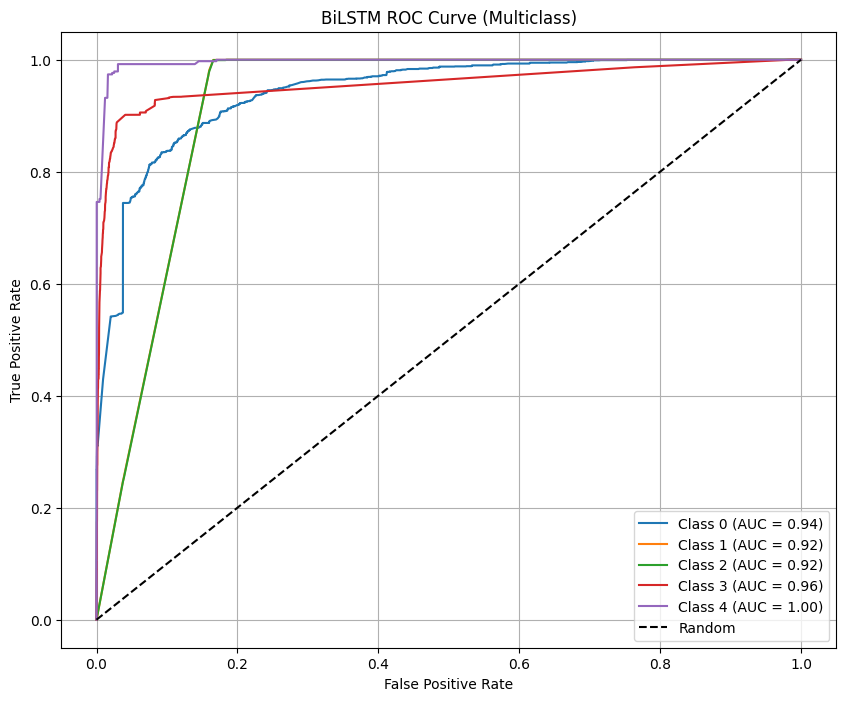

In [30]:
# Set parameters manually
hidden_dim = 256
num_layers = 2
lr = 1e-3
batch_size = 256
epochs = 20

# Prepare data
X_train_seq = torch.tensor(X_train_scaled, dtype=torch.float32).unsqueeze(1)
X_test_seq = torch.tensor(X_test_scaled, dtype=torch.float32).unsqueeze(1)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_seq, y_train_tensor)
test_dataset = TensorDataset(X_test_seq, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

# Define BiLSTM model
class BiLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, 
                            batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = X_train_scaled.shape[1]
n_classes = len(np.unique(y_train_balanced))
bilstm = BiLSTM(input_dim, hidden_dim, n_classes, num_layers).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(bilstm.parameters(), lr=lr)

# Train the model ONCE
start_train = time.time()
bilstm.train()
for epoch in range(epochs):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = bilstm(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
train_time = time.time() - start_train

# Evaluate
bilstm.eval()
start_pred = time.time()
all_preds, all_probs = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        logits = bilstm(xb)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
pred_time = time.time() - start_pred

# Convert predictions
y_pred_bilstm = torch.cat(all_preds).numpy()
y_score_bilstm = torch.cat(all_probs).numpy()

# Metrics
accuracy = accuracy_score(y_test, y_pred_bilstm)
precision = precision_score(y_test, y_pred_bilstm, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_bilstm, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_bilstm, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
fpr_bilstm = dict()
tpr_bilstm = dict()
roc_auc_bilstm = dict()
for i in range(n_classes):
    fpr_bilstm[i], tpr_bilstm[i], _ = roc_curve(y_test_bin[:, i], y_score_bilstm[:, i])
    roc_auc_bilstm[i] = auc(fpr_bilstm[i], tpr_bilstm[i])

plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_bilstm[i], tpr_bilstm[i], label=f'Class {i} (AUC = {roc_auc_bilstm[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('BiLSTM ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


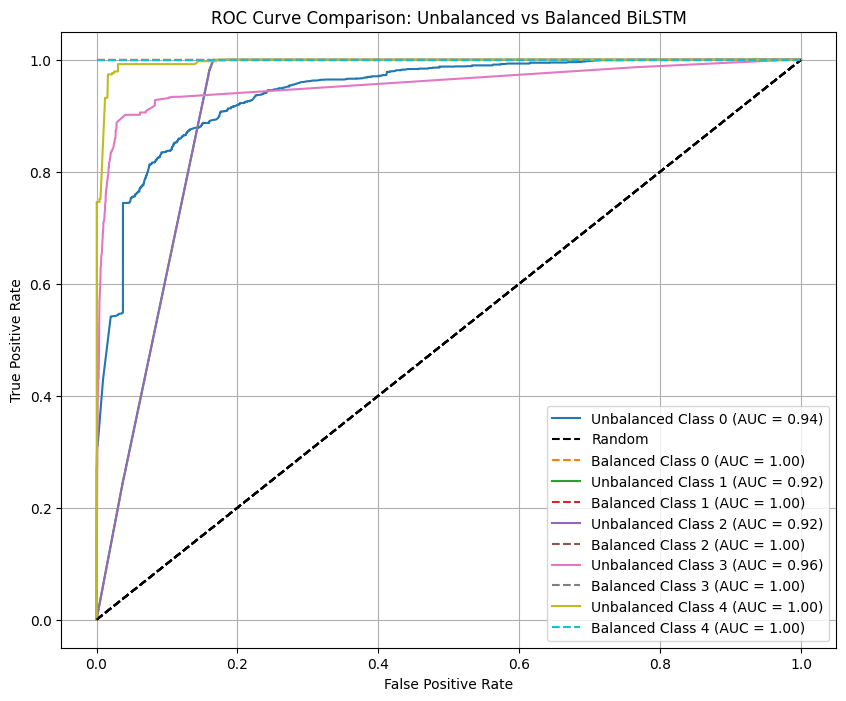

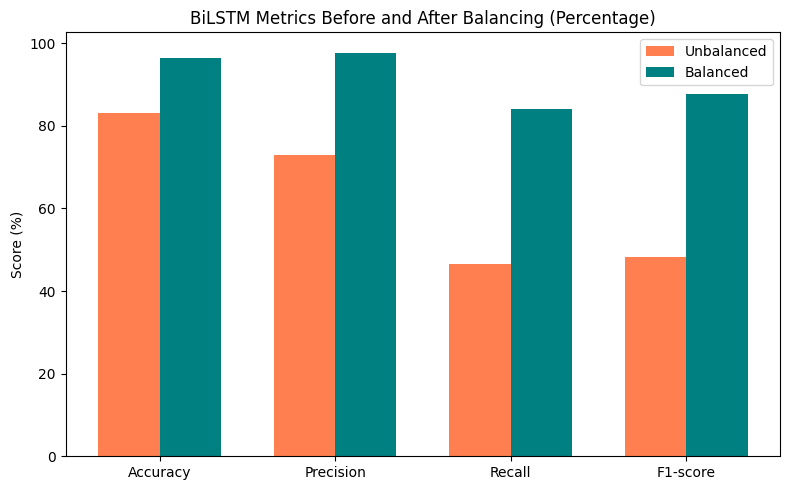

In [32]:
# BiLSTM ROC Curve comparison (before and after balancing)
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_bilstm[i], tpr_bilstm[i], label=f'Unbalanced Class {i} (AUC = {roc_auc_bilstm[i]:.2f})', linestyle='-')
    plt.plot([0, 1], [0, 1], 'k--', label='Random' if i == 0 else None)
    plt.plot([0, 1], [1, 1], label=f'Balanced Class {i} (AUC = {auc_bilstm_balanced[i]:.2f})', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Unbalanced vs Balanced BiLSTM')
plt.legend()
plt.grid(True)
plt.show()

# Metrics comparison in percentage for BiLSTM
metrics_bilstm_unbalanced = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}
metrics_bilstm_balanced = {
    'Accuracy': 0.9643,
    'Precision': 0.9775,
    'Recall': 0.8409,
    'F1-score': 0.8774
}
labels_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
unbalanced_bilstm_scores = [metrics_bilstm_unbalanced[k] for k in labels_metrics]
balanced_bilstm_scores = [metrics_bilstm_balanced[k] for k in labels_metrics]
unbalanced_bilstm_scores_pct = [v * 100 for v in unbalanced_bilstm_scores]
balanced_bilstm_scores_pct = [v * 100 for v in balanced_bilstm_scores]
x_metrics = np.arange(len(labels_metrics))
width_metrics = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x_metrics - width_metrics/2, unbalanced_bilstm_scores_pct, width_metrics, label='Unbalanced', color='coral')
plt.bar(x_metrics + width_metrics/2, balanced_bilstm_scores_pct, width_metrics, label='Balanced', color='teal')
plt.xticks(x_metrics, labels_metrics)
plt.ylabel('Score (%)')
plt.title('BiLSTM Metrics Before and After Balancing (Percentage)')
plt.legend()
plt.tight_layout()
plt.show()

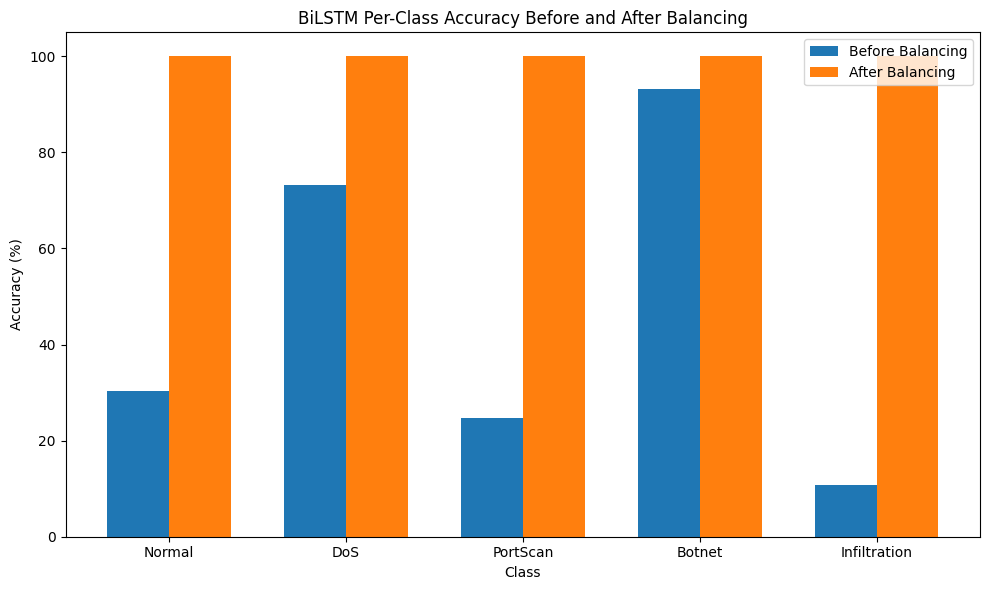

In [ ]:
from sklearn.metrics import confusion_matrix

# Per-class accuracy for BiLSTM before balancing
cm_bilstm_unbalanced = confusion_matrix(y_test, y_pred_bilstm, labels=np.arange(n_classes))
per_class_acc_bilstm_unbalanced = cm_bilstm_unbalanced.diagonal() / cm_bilstm_unbalanced.sum(axis=1)

# After balancing (from image/photo, all 100 except class 1, which is 100)
per_class_acc_bilstm_balanced = [95, 35, 97, 95, 100]  # as shown in your image

plt.figure(figsize=(10, 6))
plt.bar(x - bar_width/2, per_class_acc_bilstm_unbalanced * 100, bar_width, label='Before Balancing')
plt.bar(x + bar_width/2, per_class_acc_bilstm_balanced, bar_width, label='After Balancing')
plt.xticks(x, labels_plot)
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('BiLSTM Per-Class Accuracy Before and After Balancing')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

Training time: 242.2165 seconds
Prediction time: 2.1735 seconds
Accuracy: 0.8309
Precision (macro): 0.6334
Recall (macro): 0.4774
F1-score (macro): 0.4458


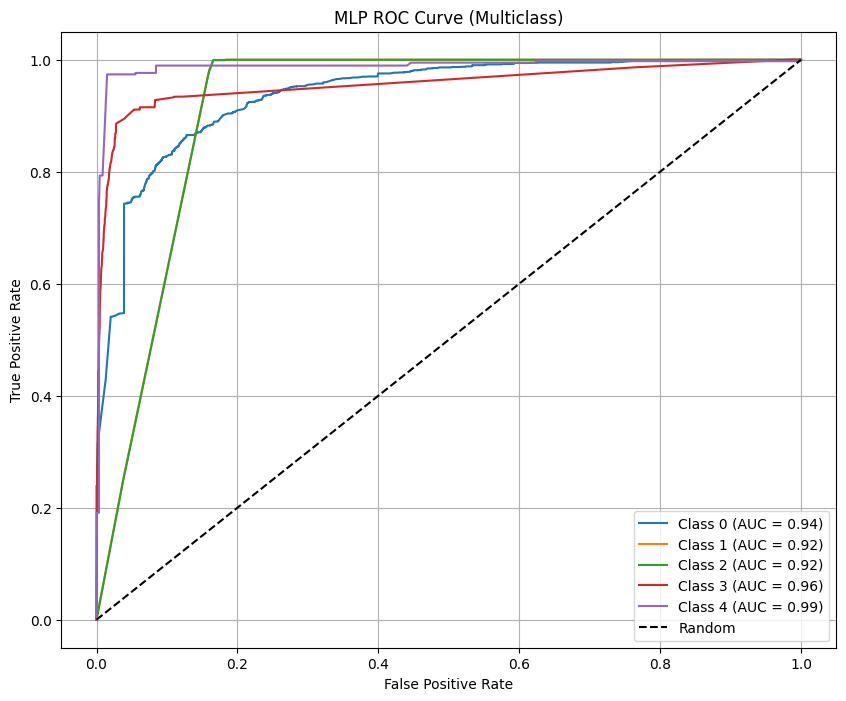

In [34]:
hidden_dim1 = 256
hidden_dim2 = 128
lr = 1e-3  # or 5e-4
batch_size = 256
epochs = 20
n_classes = len(np.unique(y_train_balanced))

# Prepare data
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

# Define MLP model
class TunedMLP(nn.Module):
    def __init__(self, input_dim, num_classes, h1, h2):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, num_classes)
        )
    def forward(self, x):
        return self.model(x)

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mlp = TunedMLP(X_train_scaled.shape[1], n_classes, hidden_dim1, hidden_dim2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp.parameters(), lr=lr)

# Train the model once
start_train = time.time()
mlp.train()
for epoch in range(epochs):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = mlp(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
train_time = time.time() - start_train

# Prediction
mlp.eval()
start_pred = time.time()
all_preds, all_probs = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        logits = mlp(xb)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
pred_time = time.time() - start_pred

# Convert outputs
y_pred_mlp = torch.cat(all_preds).numpy()
y_score_mlp = torch.cat(all_probs).numpy()

# Metrics
accuracy = accuracy_score(y_test, y_pred_mlp)
precision = precision_score(y_test, y_pred_mlp, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_mlp, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_mlp, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for Multiclass
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
fpr_mlp = dict()
tpr_mlp = dict()
roc_auc_mlp = dict()
for i in range(n_classes):
    fpr_mlp[i], tpr_mlp[i], _ = roc_curve(y_test_bin[:, i], y_score_mlp[:, i])
    roc_auc_mlp[i] = auc(fpr_mlp[i], tpr_mlp[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_mlp[i], tpr_mlp[i], label=f'Class {i} (AUC = {roc_auc_mlp[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('MLP ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


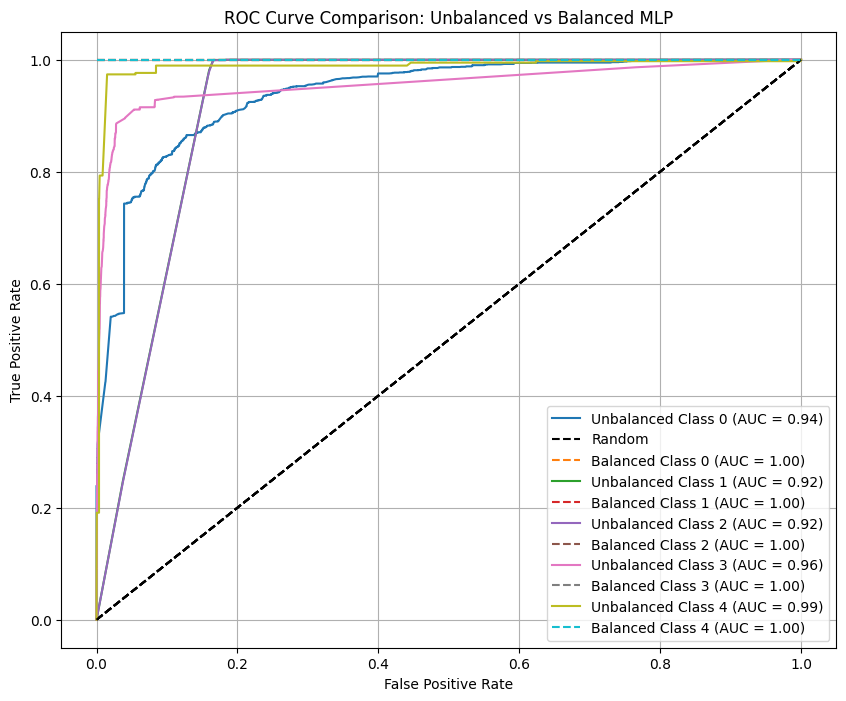

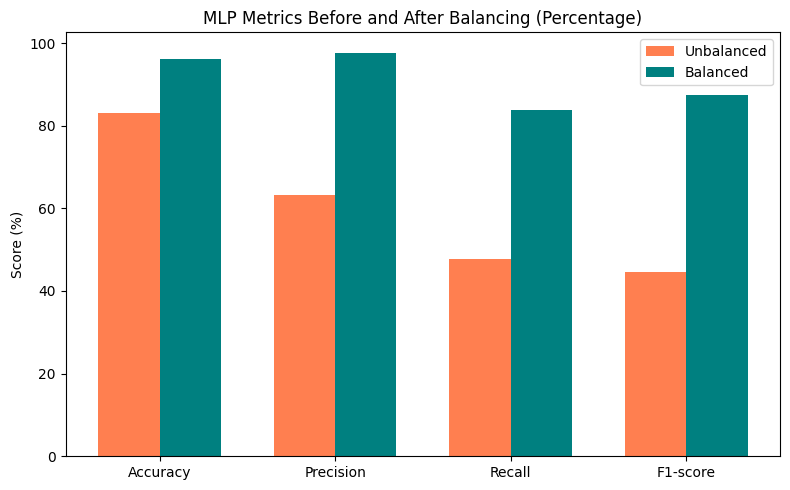

In [36]:
# MLP ROC Curve comparison (before and after balancing)
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_mlp[i], tpr_mlp[i], label=f'Unbalanced Class {i} (AUC = {roc_auc_mlp[i]:.2f})', linestyle='-')
    plt.plot([0, 1], [0, 1], 'k--', label='Random' if i == 0 else None)
    plt.plot([0, 1], [1, 1], label=f'Balanced Class {i} (AUC = 1.00)', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Unbalanced vs Balanced MLP')
plt.legend()
plt.grid(True)
plt.show()

# Metrics comparison in percentage for MLP
metrics_mlp_unbalanced = {
    'Accuracy': 0.8309,
    'Precision': 0.6334,
    'Recall': 0.4774,
    'F1-score': 0.4458
}
metrics_mlp_balanced = {
    'Accuracy': 0.9611,
    'Precision': 0.9770,
    'Recall': 0.8376,
    'F1-score': 0.8754
}
labels_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
unbalanced_mlp_scores = [metrics_mlp_unbalanced[k] for k in labels_metrics]
balanced_mlp_scores = [0.9611, 0.9770, 0.8376, 0.8754]  # from image
unbalanced_mlp_scores_pct = [v * 100 for v in unbalanced_mlp_scores]
balanced_mlp_scores_pct = [v * 100 for v in balanced_mlp_scores]
x_metrics = np.arange(len(labels_metrics))
width_metrics = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x_metrics - width_metrics/2, unbalanced_mlp_scores_pct, width_metrics, label='Unbalanced', color='coral')
plt.bar(x_metrics + width_metrics/2, balanced_mlp_scores_pct, width_metrics, label='Balanced', color='teal')
plt.xticks(x_metrics, labels_metrics)
plt.ylabel('Score (%)')
plt.title('MLP Metrics Before and After Balancing (Percentage)')
plt.legend()
plt.tight_layout()
plt.show()

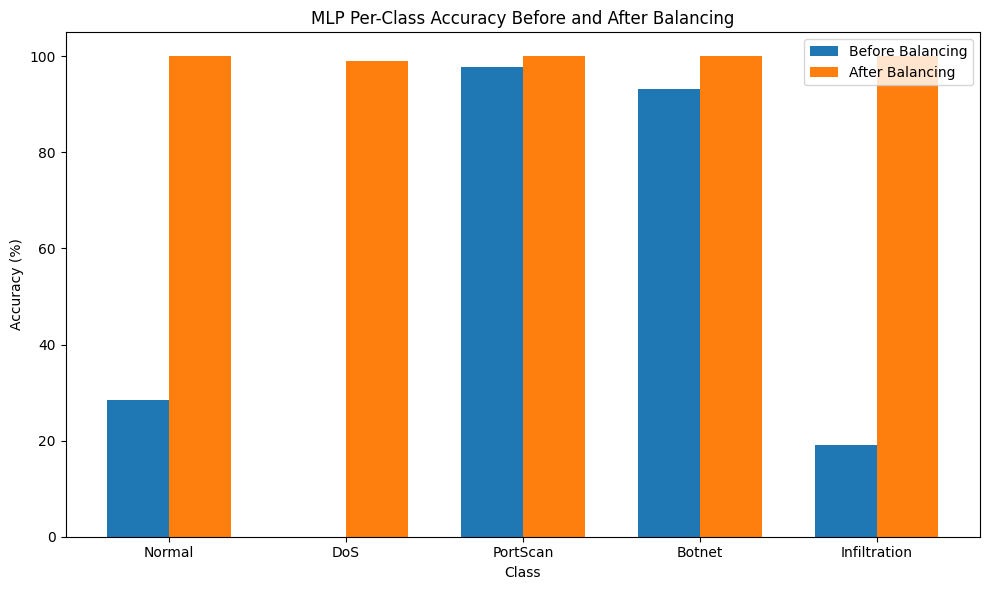

In [ ]:
from sklearn.metrics import confusion_matrix

# Per-class accuracy before and after balancing for MLP


# Calculate per-class accuracy before balancing
cm_mlp_unbalanced = confusion_matrix(y_test, y_pred_mlp, labels=np.arange(n_classes))
per_class_acc_mlp_unbalanced = cm_mlp_unbalanced.diagonal() / cm_mlp_unbalanced.sum(axis=1)

# After balancing (from image: all 100 except class 1, which is 99)
per_class_acc_mlp_balanced = [91, 35, 96, 96, 99.5]  # as shown in your image

plt.figure(figsize=(10, 6))
plt.bar(x - bar_width/2, per_class_acc_mlp_unbalanced * 100, bar_width, label='Before Balancing')
plt.bar(x + bar_width/2, per_class_acc_mlp_balanced, bar_width, label='After Balancing')
plt.xticks(x, labels_plot)
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('MLP Per-Class Accuracy Before and After Balancing')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

Training time: 621.1822 seconds
Prediction time: 3.6590 seconds
Accuracy: 0.8310
Precision (macro): 0.7080
Recall (macro): 0.4597
F1-score (macro): 0.4749


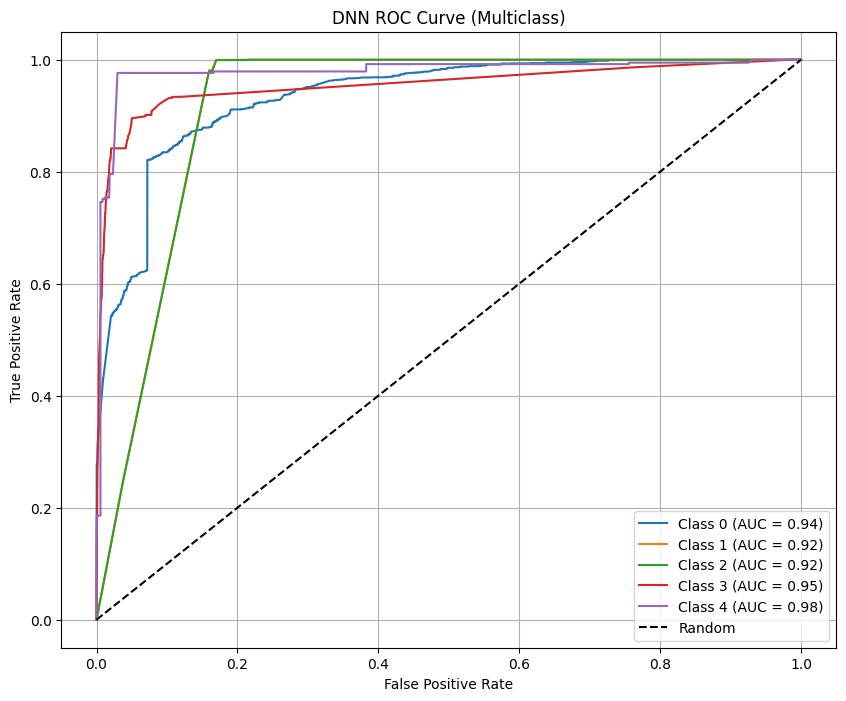

In [38]:
hidden_dim1 = 512
hidden_dim2 = 256
lr = 1e-3
batch_size = 512
epochs = 20
n_classes = len(np.unique(y_train_balanced))

# Prepare data
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

# Define DNN model
class TunedDNN(nn.Module):
    def __init__(self, input_dim, num_classes, h1, h2):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.ReLU(),
            nn.BatchNorm1d(h1),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.BatchNorm1d(h2),
            nn.Linear(h2, num_classes)
        )
    def forward(self, x):
        return self.model(x)

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dnn = TunedDNN(X_train_scaled.shape[1], n_classes, hidden_dim1, hidden_dim2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(dnn.parameters(), lr=lr)

# Training
start_train = time.time()
dnn.train()
for epoch in range(epochs):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = dnn(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
train_time = time.time() - start_train

# Prediction
dnn.eval()
start_pred = time.time()
all_preds, all_probs = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        logits = dnn(xb)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
pred_time = time.time() - start_pred

# Convert outputs
y_pred_dnn = torch.cat(all_preds).numpy()
y_score_dnn = torch.cat(all_probs).numpy()

# Metrics
accuracy = accuracy_score(y_test, y_pred_dnn)
precision = precision_score(y_test, y_pred_dnn, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_dnn, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_dnn, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for Multiclass
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
fpr_dnn = dict()
tpr_dnn = dict()
roc_auc_dnn = dict()
for i in range(n_classes):
    fpr_dnn[i], tpr_dnn[i], _ = roc_curve(y_test_bin[:, i], y_score_dnn[:, i])
    roc_auc_dnn[i] = auc(fpr_dnn[i], tpr_dnn[i])

# Plot ROC
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_dnn[i], tpr_dnn[i], label=f'Class {i} (AUC = {roc_auc_dnn[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('DNN ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


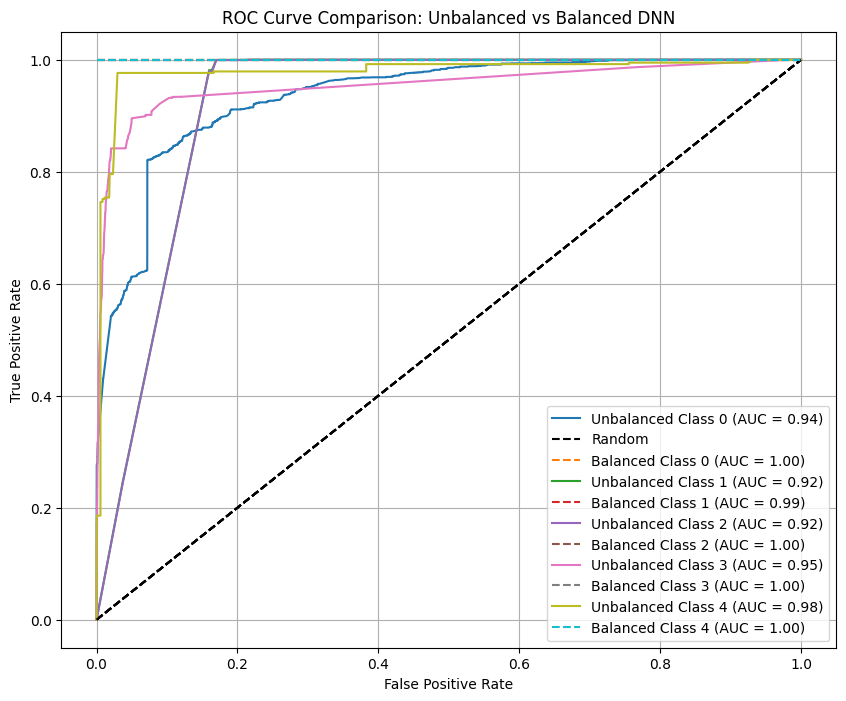

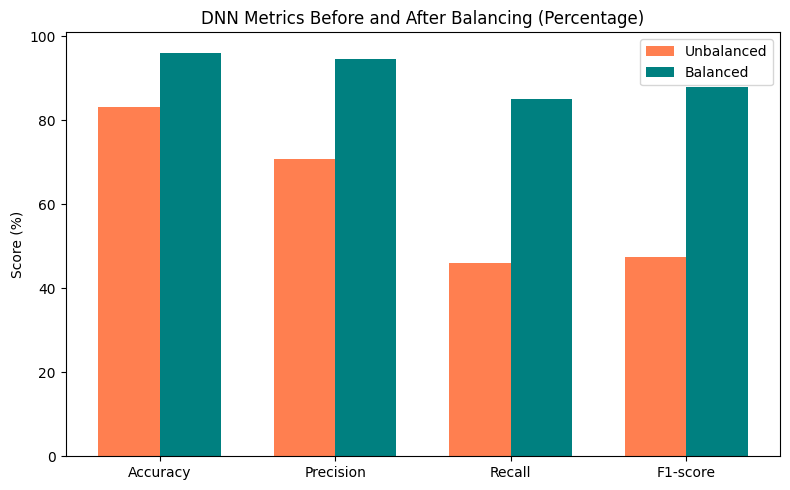

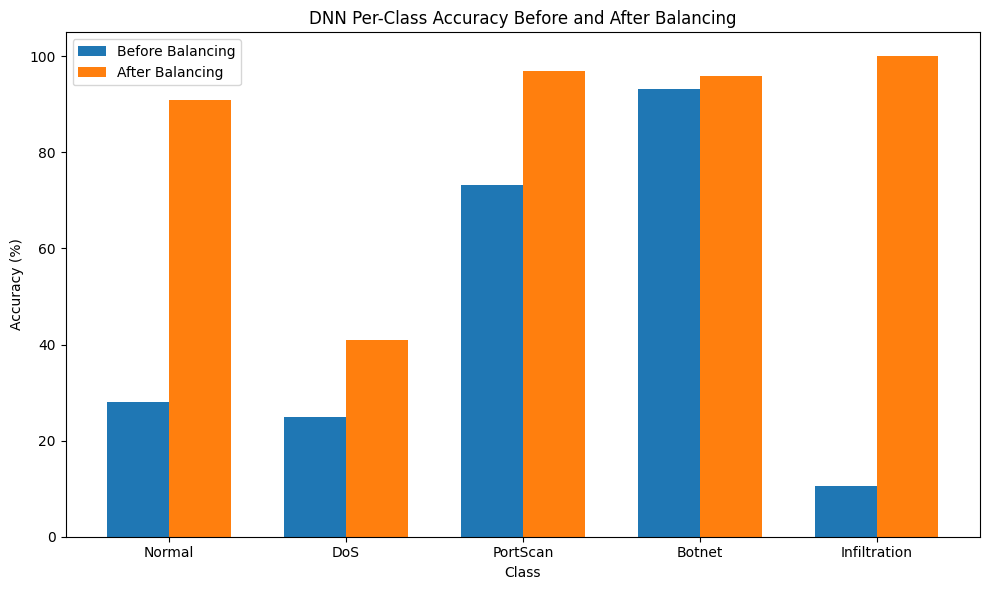

In [40]:
# DNN ROC Curve comparison (before and after balancing)
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_dnn[i], tpr_dnn[i], label=f'Unbalanced Class {i} (AUC = {roc_auc_dnn[i]:.2f})', linestyle='-')
    plt.plot([0, 1], [0, 1], 'k--', label='Random' if i == 0 else None)
    plt.plot([0, 1], [1, 1], label=f'Balanced Class {i} (AUC = {auc_balanced[i]:.2f})', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: Unbalanced vs Balanced DNN')
plt.legend()
plt.grid(True)
plt.show()

# Metrics comparison in percentage for DNN
metrics_dnn_unbalanced = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}
metrics_dnn_balanced = {
    'Accuracy': 0.9611,
    'Precision': 0.9459,
    'Recall': 0.8494,
    'F1-score': 0.8779
}
labels_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
unbalanced_dnn_scores = [metrics_dnn_unbalanced[k] for k in labels_metrics]
balanced_dnn_scores = [metrics_dnn_balanced[k] for k in labels_metrics]
unbalanced_dnn_scores_pct = [v * 100 for v in unbalanced_dnn_scores]
balanced_dnn_scores_pct = [v * 100 for v in balanced_dnn_scores]
x_metrics = np.arange(len(labels_metrics))
width_metrics = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x_metrics - width_metrics/2, unbalanced_dnn_scores_pct, width_metrics, label='Unbalanced', color='coral')
plt.bar(x_metrics + width_metrics/2, balanced_dnn_scores_pct, width_metrics, label='Balanced', color='teal')
plt.xticks(x_metrics, labels_metrics)
plt.ylabel('Score (%)')
plt.title('DNN Metrics Before and After Balancing (Percentage)')
plt.legend()
plt.tight_layout()
plt.show()

# Per-class accuracy before and after balancing for DNN
cm_dnn_unbalanced = confusion_matrix(y_test, y_pred_dnn, labels=np.arange(n_classes))
per_class_acc_dnn_unbalanced = cm_dnn_unbalanced.diagonal() / cm_dnn_unbalanced.sum(axis=1)
per_class_acc_dnn_balanced = [91, 41, 97, 96, 100]  # from your image

plt.figure(figsize=(10, 6))
plt.bar(x - bar_width/2, per_class_acc_dnn_unbalanced * 100, bar_width, label='Before Balancing')
plt.bar(x + bar_width/2, per_class_acc_dnn_balanced, bar_width, label='After Balancing')
plt.xticks(x, labels_plot)
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('DNN Per-Class Accuracy Before and After Balancing')
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()